# Appendix F | Worked solutions

*Diffusion Foundations*

Noise amplitudes are square roots of variance fractions. Exact-noise fixtures reveal the sampler algebra, while error propagation and a clipping counterexample show where apparently equivalent formulations diverge.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
from examples.ch25_visual_generation.model import add_noise, ddim_step, guided_noise


## 1. Read a noise schedule

**Problem.** For beta values 0.1 and 0.2, compute alpha values and cumulative alpha at step 2. Which quantities multiply the clean sample and the noise?

**Solution.** The individual signal variance factors are $\alpha_1=0.9$ and $\alpha_2=0.8$. Their product is $\bar\alpha_2=0.72$. The amplitudes are $a_2=\sqrt{0.72}\approx0.848528$ and $b_2=\sqrt{0.28}\approx0.529150$. Thus $x_2=a_2x_0+b_2\epsilon$. The squared amplitudes sum to one; the amplitudes themselves do not. The noise term here is the equivalent combined Gaussian at one level, not one of the individual forward increments.

Alpha: [0.9 0.8] Cumulative alpha: [0.9  0.72]
Step-two signal/noise amplitudes: 0.8485281374238571 0.529150262212918


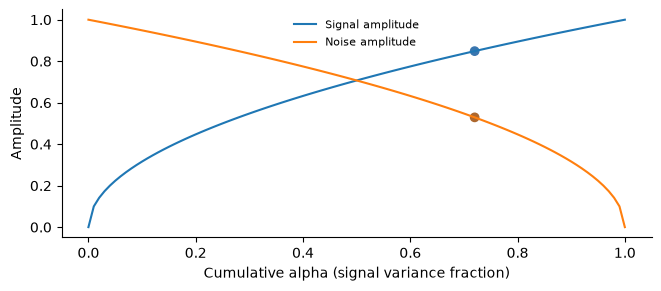

In [2]:
beta=np.array([.1,.2]);alpha=1-beta;abar=np.cumprod(alpha)
a=np.sqrt(abar[-1]);b=np.sqrt(1-abar[-1])
np.testing.assert_allclose(alpha,[.9,.8])
np.testing.assert_allclose(abar[-1],.72)
np.testing.assert_allclose(a*a+b*b,1)
print("Alpha:",alpha,"Cumulative alpha:",abar)
print("Step-two signal/noise amplitudes:",a,b)
grid=np.linspace(0,1,101)
fig,ax=plt.subplots(figsize=(6.5,2.8),layout="constrained")
ax.plot(grid,np.sqrt(grid),label="Signal amplitude")
ax.plot(grid,np.sqrt(1-grid),label="Noise amplitude")
ax.scatter([.72,.72],[a,b],color=["#3976af","#ad672d"])
ax.set(xlabel="Cumulative alpha (signal variance fraction)",ylabel="Amplitude")
ax.legend(frameon=False,fontsize=8,loc="upper center");plt.show()

## 2. Convert a velocity prediction

**Problem.** At $a=0.8$, $b=0.6$, the noisy value is 0.5 and predicted velocity is $-0.25$. Convert to clean and noise estimates. What does an epsilon sampler expect?

**Solution.** The clean estimate is $a x_t-b\widehat v=0.8(0.5)-0.6(-0.25)=0.55$. The noise estimate is $b x_t+a\widehat v=0.6(0.5)+0.8(-0.25)=0.1$. Recombining them gives $0.8(0.55)+0.6(0.1)=0.5$, the original noisy value. A noise-based sampler expects the converted epsilon estimate 0.1, not the velocity value or the clean estimate.

In [3]:
a,b,xt,v=.8,.6,.5,-.25
clean=a*xt-b*v;noise=b*xt+a*v
np.testing.assert_allclose([clean,noise],[.55,.1])
np.testing.assert_allclose(a*clean+b*noise,xt)
print("Clean estimate:",clean,"Noise estimate supplied to sampler:",noise)

Clean estimate: 0.55 Noise estimate supplied to sampler: 0.09999999999999998


## 3. Take a deterministic step

**Problem.** Call `ddim_step` for noisy value 0.3, predicted noise $-0.5$, cumulative alpha 0.64 and next cumulative alpha 0.81. Identify both outputs and the endpoint when next cumulative alpha is 1.

**Solution.** At the current level, $a_t=0.8$ and $b_t=0.6$, so $\widehat x_0=(0.3-0.6(-0.5))/0.8=0.75$. The next sample is $0.9(0.75)+\sqrt{0.19}(-0.5)=0.675-0.5\sqrt{0.19}\approx0.457055$. The function returns the clean estimate first and the next noisy sample second. At the endpoint, the next sample equals 0.75 because its signal amplitude is one and noise amplitude zero; the clean estimate itself remains 0.75. The step uses no fresh random noise.

In [4]:
clean,next_sample=ddim_step(.3,-.5,.64,.81)
end_clean,end_sample=ddim_step(.3,-.5,.64,1.)
np.testing.assert_allclose([clean,next_sample],[.75,.675-.5*np.sqrt(.19)])
np.testing.assert_allclose([end_clean,end_sample],[.75,.75])
print("Clean estimate:",clean,"Next sample:",next_sample)
print("Endpoint outputs:",end_clean,end_sample)

Clean estimate: 0.7499999999999999 Next sample: 0.4570550528229663
Endpoint outputs: 0.7499999999999999 0.7499999999999999


## 4. Keep frame and noise axes distinct

**Problem.** A video has six frames, height 32, width 48, and three pixel channels. Give noise shape in frame/height/width/channel order. If conditional and unconditional predictions differ, which guidance scale returns the conditional one? What shape changes?

**Solution.** The unbatched noise shape is $[6,32,48,3]$, matching the sample. Guidance $u+g(c-u)$ returns $c$ at $g=1$; because the two arrays differ, this scale is unique. Changing the scale changes values, not frame count, spatial dimensions, or channel count. The frame axis indexes positions in the video; the diffusion step is a separate noise-level input for the whole sample.

In [5]:
shape=(6,32,48,3)
u=np.zeros(shape);c=np.ones(shape)
conditional=guided_noise(u,c,1.)
extrapolated=guided_noise(u,c,2.)
np.testing.assert_array_equal(conditional,c)
assert conditional.shape==extrapolated.shape==shape
print("Noise and prediction shape:",shape)
print("Scale 1 value:",conditional[0,0,0,0],
      "Scale 2 value:",extrapolated[0,0,0,0])

Noise and prediction shape: (6, 32, 48, 3)
Scale 1 value: 1.0 Scale 2 value: 2.0


## 5. Add independent variances

**Problem.** For two beta values 0.2, derive the two noise coefficients and combined variance. What if both increments reuse the same Gaussian? Also find noisy variance when the clean coordinate has variance four, independent of the noise.

**Solution.** Substitution gives $x_2=0.8x_0+0.4z_1+\sqrt{0.2}z_2$. With independent unit-variance increments, the noise variance is $0.4^2+(\sqrt{0.2})^2=0.16+0.2=0.36$, so its equivalent amplitude is 0.6. Reusing a draw makes the noise $(0.4+\sqrt{0.2})z$ with variance about 0.717771; the positive covariance adds a cross term. For clean variance four and the original independent increments, total noisy variance is $0.8^2(4)+0.36=2.92$. It is not automatically one. A deterministic covariance calculation checks these answers without Monte Carlo sampling error.

In [6]:
coeff=np.array([np.sqrt(.8*.2),np.sqrt(.2)])
independent=coeff@np.eye(2)@coeff
shared=coeff@np.ones((2,2))@coeff
clean_variance=4.;total=.64*clean_variance+independent
np.testing.assert_allclose(independent,.36)
np.testing.assert_allclose(shared,(.4+np.sqrt(.2))**2)
np.testing.assert_allclose(total,2.92)
print("Noise coefficients:",coeff)
print("Independent noise variance:",independent)
print("Shared-draw noise variance:",shared)
print("Noisy variance with clean variance four:",total)

Noise coefficients: [0.4      0.447214]
Independent noise variance: 0.36
Shared-draw noise variance: 0.7177708763999664
Noisy variance with clean variance four: 2.92


## 6. Test the rotation including endpoints

**Problem.** Choose fixed clean and noise arrays. For $a=0,0.8,1$ and $b=\sqrt{1-a^2}$, form noisy values and velocities, then recover both inputs. Which endpoint prevents epsilon-to-clean division?

**Solution.** The forward pair is $x=a x_0+b\epsilon$ and $v=-b x_0+a\epsilon$. Multiplying by the inverse rotation gives $x_0=a x-b v$ and $\epsilon=b x+a v$. At $a=0$, $x=\epsilon$ and $v=-x_0$, so both remain recoverable from the pair $(x,v)$. Epsilon-to-clean division $(x-b\epsilon)/a$ is undefined there because the noisy value alone contains no clean contribution. At $a=1$, $x=x_0$ and $v=\epsilon$. These tests verify identities on supplied pairs; a learned model must still predict the needed second coordinate.

In [7]:
clean=np.array([[-1.,.5],[2.,-3.]])
noise=np.array([[2.,-1.],[.25,1.5]])
for a in [0.,.8,1.]:
    b=np.sqrt(1-a*a)
    noisy=add_noise(clean,noise,a*a)
    velocity=a*noise-b*clean
    recovered_clean=a*noisy-b*velocity
    recovered_noise=b*noisy+a*velocity
    np.testing.assert_allclose(recovered_clean,clean,atol=1e-14)
    np.testing.assert_allclose(recovered_noise,noise,atol=1e-14)
    print(f"a={a:.1f}: maximum clean/noise errors",
          np.max(np.abs(recovered_clean-clean)),
          np.max(np.abs(recovered_noise-noise)))
try:
    ddim_step(noise,noise,0.,.64)
except ValueError:
    print("Epsilon DDIM correctly rejects a=0.")
else:
    raise AssertionError("Division by zero endpoint must be rejected")

a=0.0: maximum clean/noise errors 0.0 0.0
a=0.8: maximum clean/noise errors 0.0 4.440892098500626e-16
a=1.0: maximum clean/noise errors 0.0 0.0
Epsilon DDIM correctly rejects a=0.


## 7. Measure error amplification

**Problem.** Hold a clean scalar and noise draw fixed and add noise-prediction error 0.02. Compare clean-estimate errors at $a=0.8$ and $a=0.1$ with $-(b/a)\delta$. Why is this not a denoiser benchmark?

**Solution.** Choose $x_0=-1$ and $\epsilon=2$. The sampler sees the corresponding noisy value at each level, but the supplied prediction is 2.02. At $a=0.8$, $b=0.6$, so the clean error is $-(0.6/0.8)(0.02)=-0.015$. At $a=0.1$, it is $-\sqrt{0.99}(0.02)/0.1\approx-0.198997$. The same epsilon error is amplified more at low signal amplitude. No model was trained or queried: the experiment specifies its errors by hand and checks the algebra. It does not establish which parameterization learns more accurately.

a=0.8: observed error=-0.015000000, predicted=-0.015000000
a=0.1: observed error=-0.198997487, predicted=-0.198997487


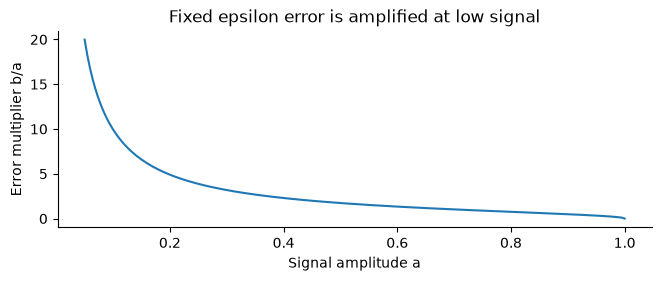

In [8]:
clean,noise,delta=-1.,2.,.02
for a in [.8,.1]:
    b=np.sqrt(1-a*a)
    noisy=add_noise(clean,noise,a*a)
    estimate,_=ddim_step(noisy,noise+delta,a*a,1.)
    error=estimate-clean;expected=-b/a*delta
    np.testing.assert_allclose(error,expected,atol=1e-14)
    print(f"a={a:.1f}: observed error={error:.9f}, predicted={expected:.9f}")
a_grid=np.linspace(.05,1,200)
fig,ax=plt.subplots(figsize=(6.5,2.7),layout="constrained")
ax.plot(a_grid,np.sqrt(1-a_grid*a_grid)/a_grid)
ax.set(xlabel="Signal amplitude a",ylabel="Error multiplier b/a",
       title="Fixed epsilon error is amplified at low signal")
plt.show()

## 8. Check guidance and conversion order

**Problem.** Use noisy value 0.5, $a=0.8$, $b=0.6$, unconditional velocity $-1$, conditional velocity 0.5, and guidance 2. Compare guidance before/after conversion to noise. Then clip the guided velocity before conversion versus clipping final guided noise, both to $[-1,1]$.

**Solution.** The guided velocity is $-1+2(0.5+1)=2$, which converts to $0.6(0.5)+0.8(2)=1.9$. Separate conversion gives unconditional noise $-0.5$ and conditional noise 0.7; guiding gives $-0.5+2(0.7+0.5)=1.9$. Equality holds because the same affine map is applied and the guidance weights sum to one. Clipping the guided velocity to 1 before conversion gives $0.3+0.8(1)=1.1$. Clipping the final guided noise 1.9 gives 1. The nonlinear clips act in different coordinate systems, so the two routes no longer agree.

In [9]:
xt,a,b,vu,vc,g=.5,.8,.6,-1.,.5,2.
convert=lambda v: b*xt+a*v
guided_velocity=vu+g*(vc-vu)
route_one=convert(guided_velocity)
route_two=guided_noise(convert(vu),convert(vc),g)
np.testing.assert_allclose([route_one,route_two],[1.9,1.9])
clip_velocity=convert(np.clip(guided_velocity,-1,1))
clip_noise=np.clip(route_two,-1,1)
np.testing.assert_allclose([clip_velocity,clip_noise],[1.1,1.])
assert not np.isclose(clip_velocity,clip_noise)
print("Without clipping:",route_one,route_two)
print("Clip velocity then convert:",clip_velocity)
print("Guide noise then clip:",clip_noise)

Without clipping: 1.9000000000000001 1.9
Clip velocity then convert: 1.1
Guide noise then clip: 1.0
